## EXPLANATION DATASET
Gender classification Problem

This dataset represents a binary classification of two genders defined by physical characteristics of each person in the record of our data set, these characteristics are the followings:

1) If it has or not long hair
2) The length of its forehead
3) The height of the forehead
4) If the noise is wide or not 
5) if they have thin libs or not 
6) The distance from noise to lib

With these characteristics we are trying to find the best SVM model adjusting the hyperparameters as much as its needed to perform in a perfect way this model 

## LOAD DATA

In [ ]:
import pandas as pd
import numpy as np

data = pd.read_csv('../data/gender.csv')

In [ ]:
data.info()
data.describe(include='all')
display(data.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5001 entries, 0 to 5000
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   long_hair                  5001 non-null   int64  
 1   forehead_width_cm          5001 non-null   float64
 2   forehead_height_cm         5001 non-null   float64
 3   nose_wide                  5001 non-null   int64  
 4   nose_long                  5001 non-null   int64  
 5   lips_thin                  5001 non-null   int64  
 6   distance_nose_to_lip_long  5001 non-null   int64  
 7   gender                     5001 non-null   object 
dtypes: float64(2), int64(5), object(1)
memory usage: 312.7+ KB


,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,Male
1,0,14.0,5.4,0,0,1,0,Female
2,0,11.8,6.3,1,1,1,1,Male
3,0,14.4,6.1,0,1,1,1,Male
4,1,13.5,5.9,0,0,0,0,Female


## DATA CLEANING
1) Check for missing values on the dataset
2) check for potential outliers on the dataset

In [ ]:
# Ckeck for missing values
missing_values = data.isnull().sum()
na_values = data.isna().sum

print("Missing values on each column:")
print(missing_values)

print("Nan values on each column:")
print(na_values)

Missing values on each column:
long_hair                    0
forehead_width_cm            0
forehead_height_cm           0
nose_wide                    0
nose_long                    0
lips_thin                    0
distance_nose_to_lip_long    0
gender                       0
dtype: int64
Nan values on each column:
<bound method DataFrame.sum of       long_hair  forehead_width_cm  forehead_height_cm  nose_wide  nose_long  \
0         False              False               False      False      False   
1         False              False               False      False      False   
2         False              False               False      False      False   
3         False              False               False      False      False   
4         False              False               False      False      False   
...         ...                ...                 ...        ...        ...   
4996      False              False               False      False      False   
4997      

As we can clearly see we dont any any problem related with missing values on this data set 

OUTLIERS

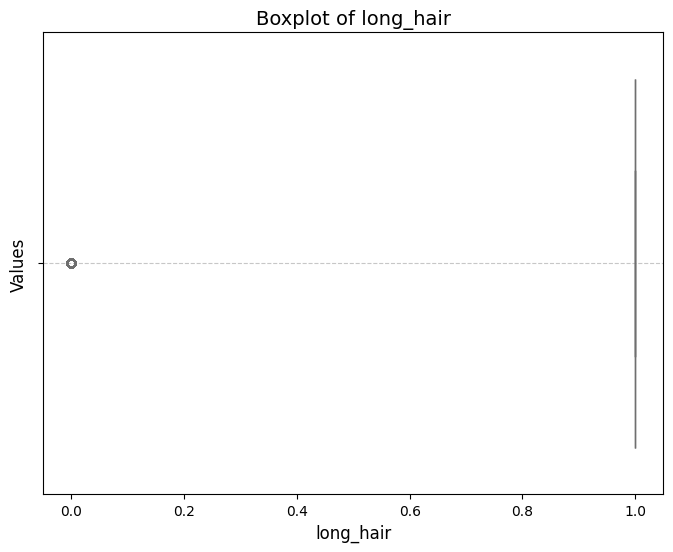

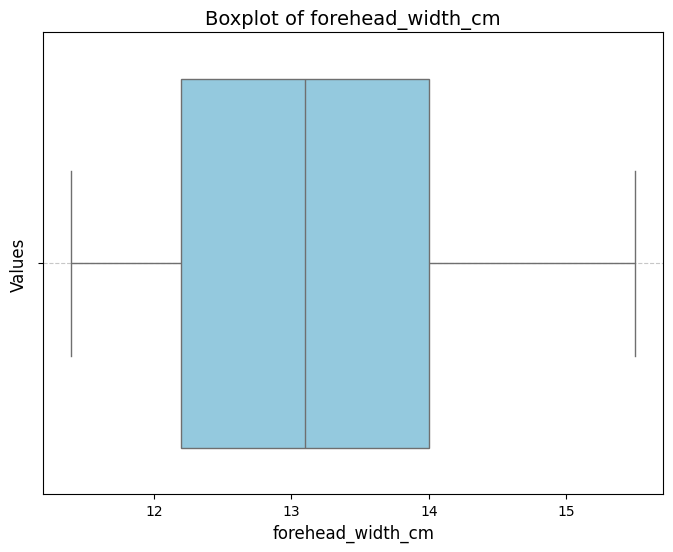

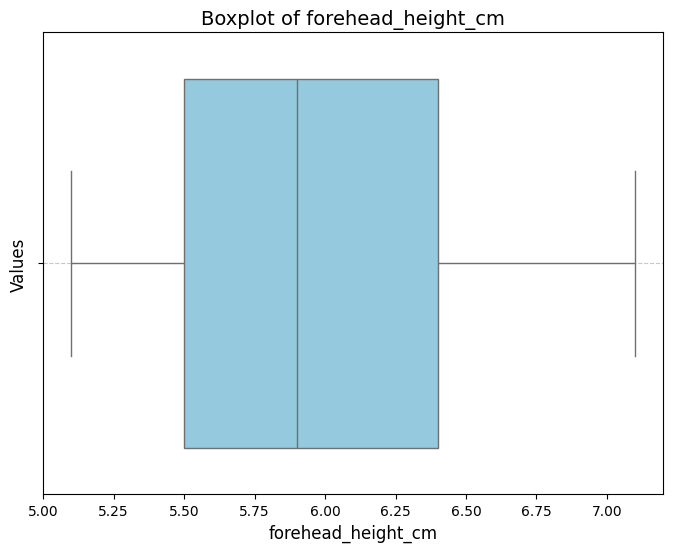

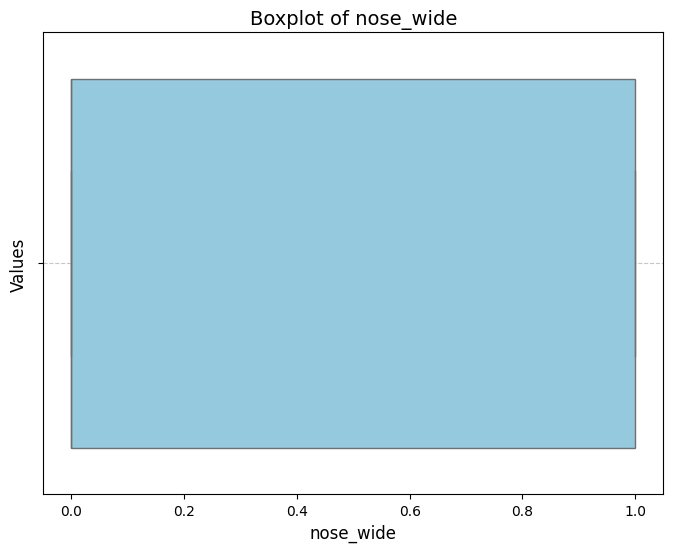

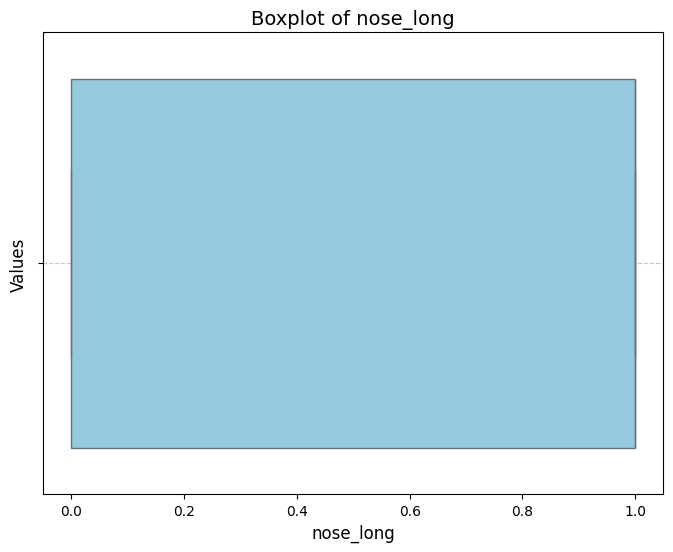

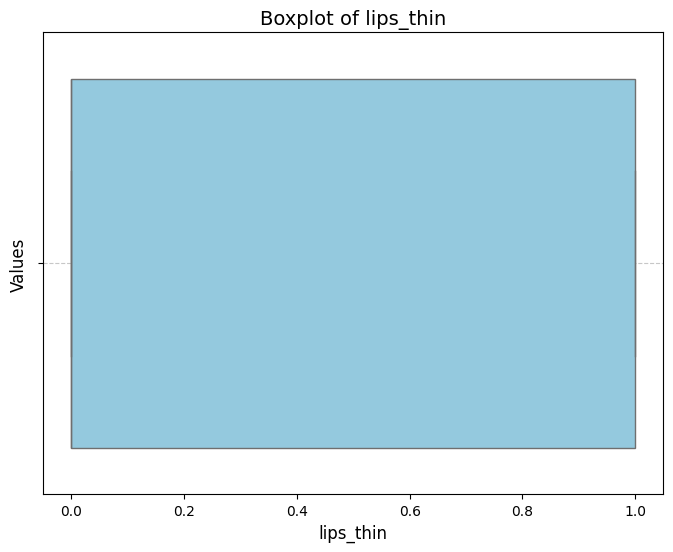

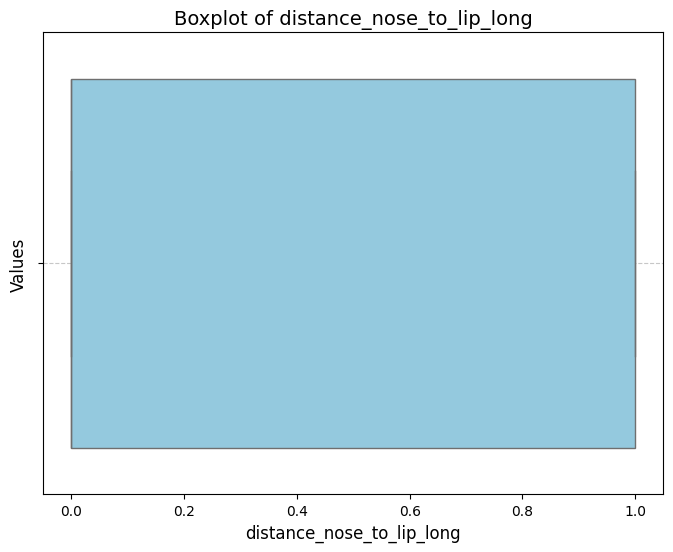

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_all_boxplots(df, color="skyblue"):
    """
    Genera boxplots para todas las columnas numéricas de un DataFrame.

    Parámetros:
    -----------
    df : pd.DataFrame
        El DataFrame que contiene las características a visualizar.
    color : str, default="skyblue"
        El color de los boxplots.

    Retorna:
    --------
    None
    """
    # Filtrar solo las columnas numéricas
    numeric_columns = df.select_dtypes(include=['number']).columns

    for feature in numeric_columns:
        plt.figure(figsize=(8, 6))
        sns.boxplot(data=df, x=feature, color=color)
        plt.title(f"Boxplot of {feature}", fontsize=14)
        plt.xlabel(feature, fontsize=12)
        plt.ylabel("Values", fontsize=12)
        plt.grid(axis="y", linestyle="--", alpha=0.7)
        plt.show()
plot_all_boxplots(data)

There´s no outliers as we can see on the boxplot of each feature that we mentioned on the beginning 

## FEATURE ENGINEERING
1) change our target variable (gender) to a binary variable by label encoder 
2) We combine features in order to make new ones and simplify the model
3) Plot all te histograms against the target value to visualize better the dataset 
4) Correlation matrix

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

def label_encode_column(df, column_name):
    """
    Performs Label Encoding on a specified column using Scikit-learn's LabelEncoder.

    Args:
        df (pd.DataFrame): The DataFrame containing the data.
        column_name (str): The name of the column to encode.

    Returns:
        pd.DataFrame: A new DataFrame with the label-encoded column.
    """
    # Initialize the label encoder
    encoder = LabelEncoder()
    
    # Fit and transform the specified column
    df[column_name] = encoder.fit_transform(df[column_name])
    
    return df

label_encode_column(data, 'gender')


display(data.head())

,long_hair,forehead_width_cm,forehead_height_cm,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender
0,1,11.8,6.1,1,0,1,1,1
1,0,14.0,5.4,0,0,1,0,0
2,0,11.8,6.3,1,1,1,1,1
3,0,14.4,6.1,0,1,1,1,1
4,1,13.5,5.9,0,0,0,0,0


We combine the forehead_width_cm and forehead_height_cm into one single feature.
This new feature will be the ratio = forehead_width / forehead_height

In [ ]:
# Combine forehead width and height into a single feature
data['forehead_ratio'] = data['forehead_width_cm'] / data['forehead_height_cm']

# Handle potential division by zero or infinite values
data['forehead_ratio'] = data['forehead_ratio'].replace([np.inf, -np.inf], np.nan).fillna(data['forehead_ratio'].mean())

# Remove the original columns
data = data.drop(['forehead_width_cm', 'forehead_height_cm'], axis=1)

display(data.head())

,long_hair,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender,forehead_ratio
0,1,1,0,1,1,1,1.934426
1,0,0,0,1,0,0,2.592593
2,0,1,1,1,1,1,1.873016
3,0,0,1,1,1,1,2.360656
4,1,0,0,0,0,0,2.288136


In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

def standardize_features(data, features):
    """
    Estandariza características específicas del dataset.
    
    Parameters:
    - data: DataFrame con los datos.
    - features: Lista de características a estandarizar.
    
    Returns:
    - DataFrame con las características seleccionadas estandarizadas.
    """
    # Copia del dataset para no modificar el original
    data_standardized = data.copy()
    
    # Crear el escalador y aplicar a las características seleccionadas
    scaler = StandardScaler()
    data_standardized[features] = scaler.fit_transform(data[features])
    
    return data_standardized

standardize_features(data, ['forehead_ratio'])

,long_hair,nose_wide,nose_long,lips_thin,distance_nose_to_lip_long,gender,forehead_ratio
0,1,1,0,1,1,1,-1.131167
1,0,0,0,1,0,0,1.357185
2,0,1,1,1,1,1,-1.363344
3,0,0,1,1,1,1,0.480293
4,1,0,0,0,0,0,0.206114
...,...,...,...,...,...,...,...
4996,1,0,0,0,0,0,1.637239
4997,1,0,0,0,0,0,-0.113101
4998,1,0,0,0,0,0,0.111680
4999,1,0,0,0,0,0,-0.395414


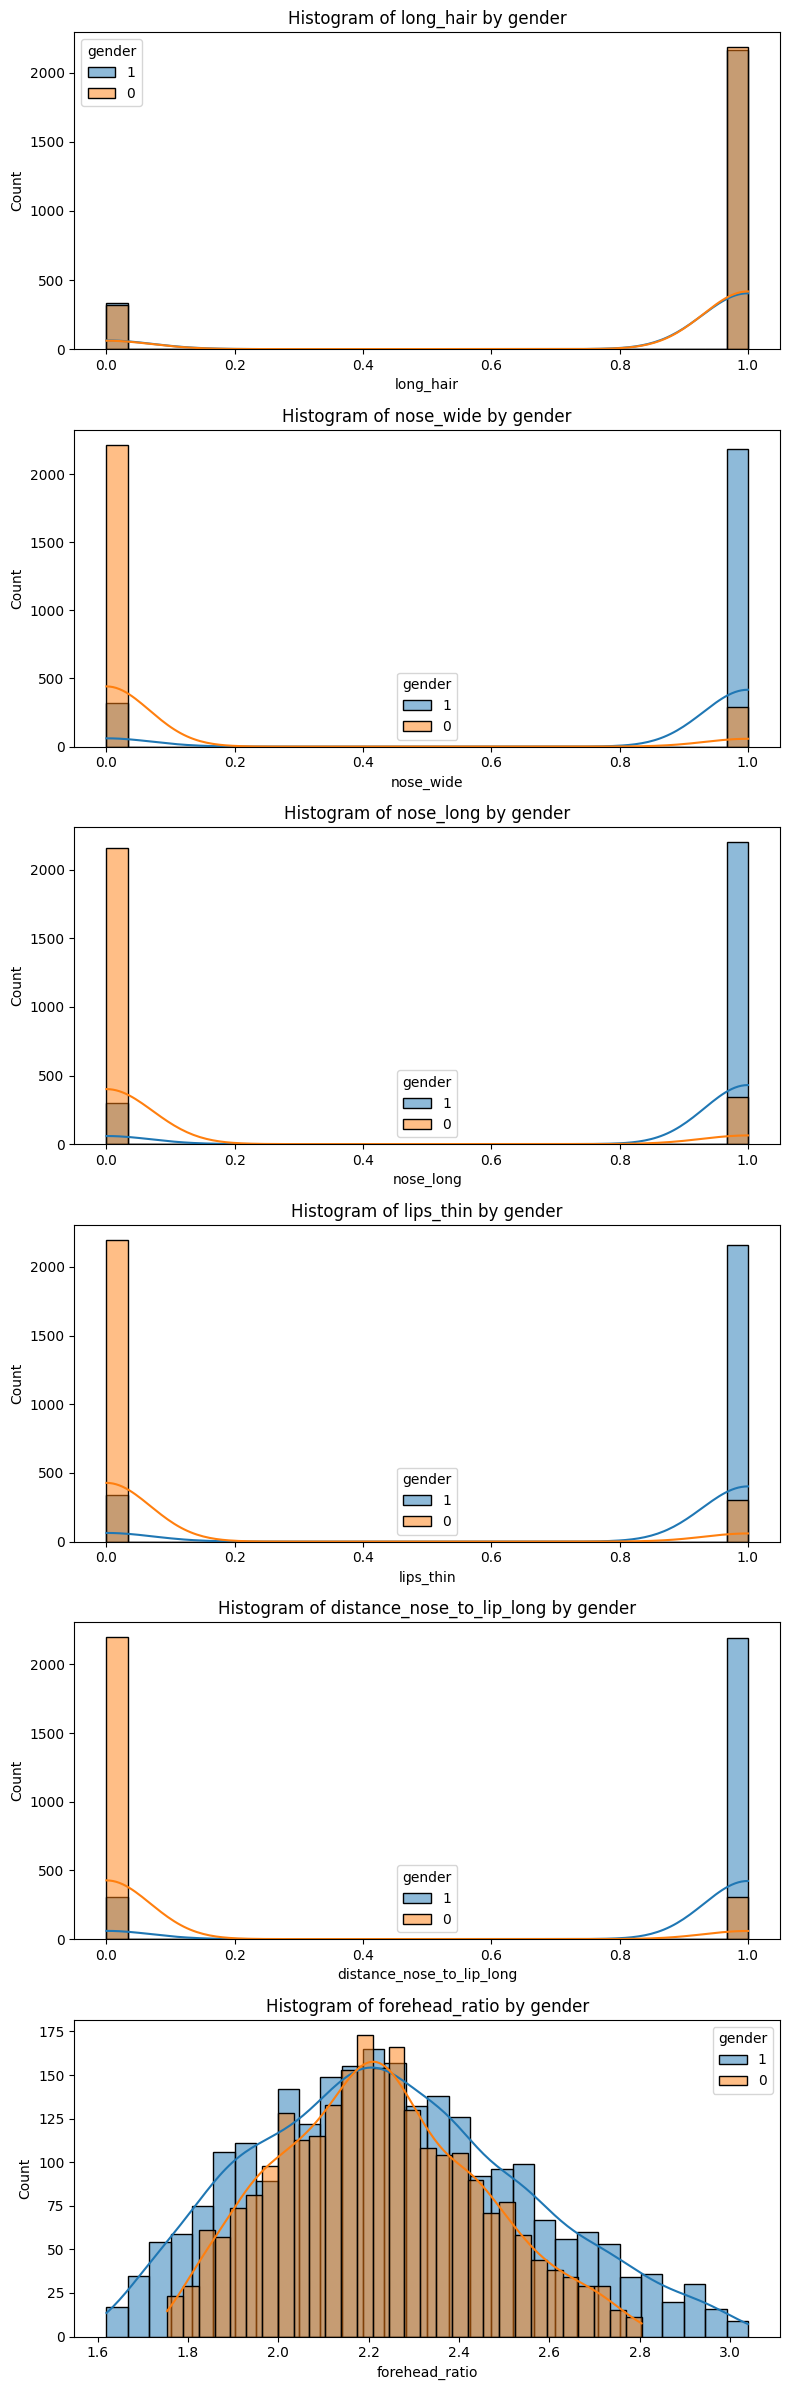

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_feature_histograms(df, target_feature, bins=30):
    """
    Genera histogramas de todas las características numéricas en función de una variable objetivo.

    Parámetros:
    - df: DataFrame de pandas
    - target_feature: Nombre de la columna objetivo (debe ser categórica o discreta)
    - bins: Número de bins para los histogramas
    """
    numeric_features = df.select_dtypes(include=['number']).columns
    numeric_features = [col for col in numeric_features if col != target_feature]
    
    unique_classes = df[target_feature].unique()
    num_features = len(numeric_features)
    
    fig, axes = plt.subplots(nrows=num_features, ncols=1, figsize=(8, 4 * num_features))
    
    if num_features == 1:
        axes = [axes]  # Asegura que axes sea iterable cuando hay solo una feature
    
    for ax, feature in zip(axes, numeric_features):
        for category in unique_classes:
            sns.histplot(df[df[target_feature] == category][feature], bins=bins, label=str(category), alpha=0.5, ax=ax, kde=True)
        
        ax.set_title(f'Histogram of {feature} by {target_feature}')
        ax.legend(title=target_feature)
    
    plt.tight_layout()
    plt.show()

plot_feature_histograms(data, 'gender')

Correlation matrix

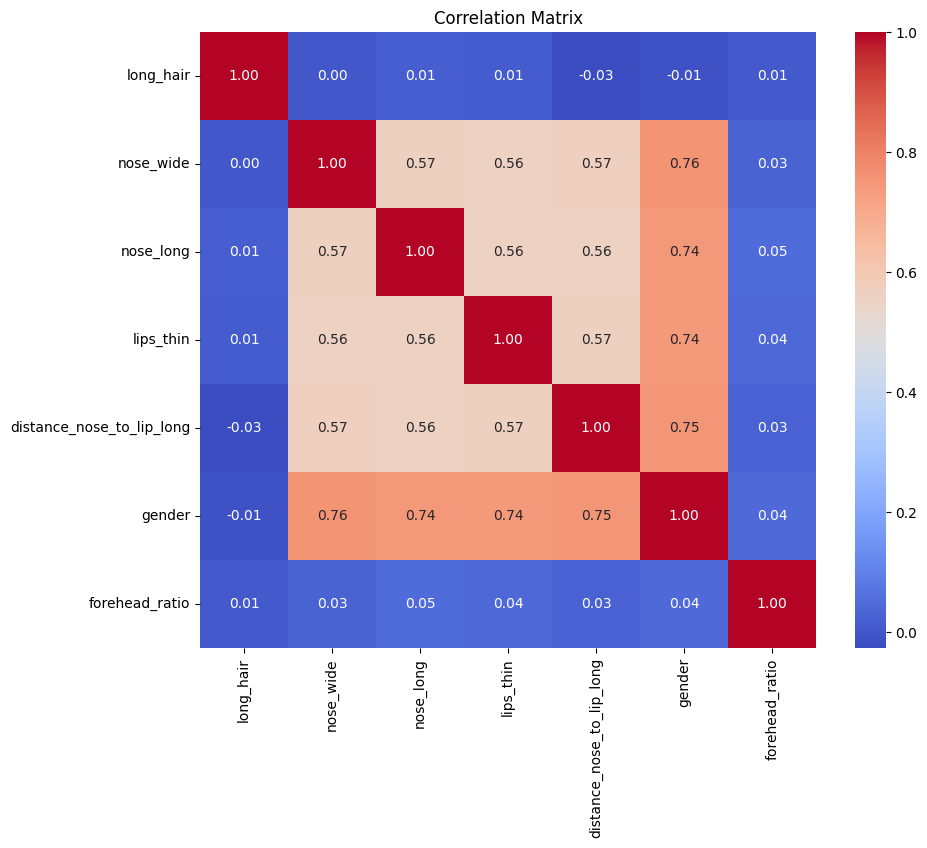

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#MATRIZ DE CORRELACIÓN

def plot_correlation_matrix(data):
    """
    Plot a correlation matrix for all features in the dataset.

    Parameters:
    data (DataFrame): The input DataFrame containing all features.

    Returns:
    None
    """
    plt.figure(figsize=(10, 8))
    correlation_matrix = data.corr()
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar=True)
    plt.title("Correlation Matrix")
    plt.show()
plot_correlation_matrix(data)

## TRAIN AND TEST 
1) Split the data into train and test
2) Then we are gonna try to use the three types of SVM that we have learnt 
3) In each of them we are gonna perform the hyperparameter tuning to get the best value out of each one 
4) Summary of the results obtain and analysis of the hyperparameters used 


In [ ]:
from sklearn.model_selection import train_test_split
X = data.drop('gender',axis=1)
y = data['gender']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

We now proceed to train and test the three types of SVM that we know :
1) Linear
2) Polynomial 
3) Gaussian 

## SVM LIENAR

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

# Create the  pipeline
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', random_state=42,C=1))
])

# Ajust the model
pipeline.fit(X_train, y_train)

# presict the target
y_pred = pipeline.predict(X_test)

# Calculate the accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.9530469530469531

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       502
           1       0.96      0.95      0.95       499

    accuracy                           0.95      1001
   macro avg       0.95      0.95      0.95      1001
weighted avg       0.95      0.95      0.95      1001



This accuracy we get it with the usual hyperparameters , C = 1, now we can try some different values in order to reach the best accuracy 

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import GridSearchCV

# Manual hyperparameter tuning
# First attempt with default parameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Default parameters results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Second attempt with modified hyperparameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=0.5, tol=1e-3, random_state=42))  # Adjusted C and tol
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("\nModified parameters results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Third attempt with modified hyperparameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='linear', C=0.3, tol=1e-5, random_state=42))  # Adjusted C and tol
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("\nModified parameters results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# GridSearch for best parameters
param_grid = {
    'svm__C': [0.1, 0.5, 1, 10],
    'svm__tol': [1e-4, 1e-3, 1e-2],
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5)
grid_search.fit(X_train, y_train)

print("\nBest parameters found:")
print(grid_search.best_params_)

y_pred = grid_search.predict(X_test)
print("\nBest model results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Default parameters results:
Accuracy: 0.9530469530469531
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       502
           1       0.96      0.95      0.95       499

    accuracy                           0.95      1001
   macro avg       0.95      0.95      0.95      1001
weighted avg       0.95      0.95      0.95      1001


Modified parameters results:
Accuracy: 0.9530469530469531
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       502
           1       0.96      0.95      0.95       499

    accuracy                           0.95      1001
   macro avg       0.95      0.95      0.95      1001
weighted avg       0.95      0.95      0.95      1001


Modified parameters results:
Accuracy: 0.9530469530469531
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       502
           1       0.96      0.95      0.95       499

    acc

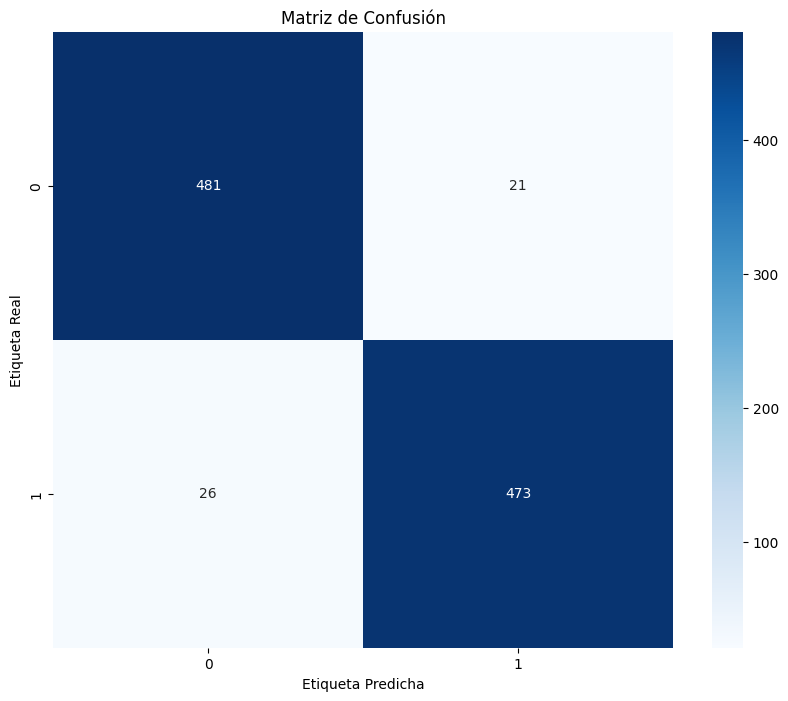

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.show()


Now we do it for the polynomial 

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import GridSearchCV

# First attempt with default polynomial kernel parameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='poly', random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Default polynomial kernel results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Second attempt with modified hyperparameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='poly', degree=3, C=1, coef0=1, random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("\nModified polynomial kernel results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Third attempt with modified hyperparameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='poly', degree=4, C=0.7, coef0=1, random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("\nModified polynomial kernel results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# GridSearch for best parameters
param_grid = {
    'svm__C': [0.1, 1, 10],
    'svm__degree': [2, 3, 4],
    'svm__coef0': [0, 1, 2]
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5)
grid_search.fit(X_train, y_train)

print("\nBest parameters found:")
print(grid_search.best_params_)

y_pred = grid_search.predict(X_test)
print("\nBest model results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Default polynomial kernel results:
Accuracy: 0.957042957042957
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       502
           1       0.95      0.96      0.96       499

    accuracy                           0.96      1001
   macro avg       0.96      0.96      0.96      1001
weighted avg       0.96      0.96      0.96      1001


Modified polynomial kernel results:
Accuracy: 0.965034965034965
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       502
           1       0.96      0.97      0.96       499

    accuracy                           0.97      1001
   macro avg       0.97      0.97      0.97      1001
weighted avg       0.97      0.97      0.97      1001


Modified polynomial kernel results:
Accuracy: 0.9660339660339661
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       502
           1       0.97      0.97      0.97

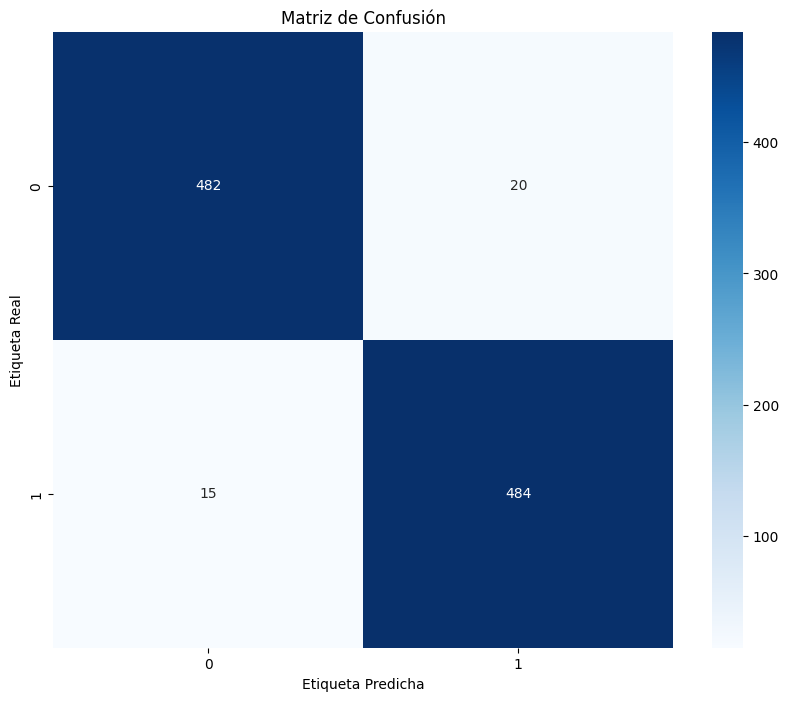

In [ ]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.show()

And now with the rbf

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import GridSearchCV

# First attempt with default Gaussian (RBF) kernel parameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("Default Gaussian kernel results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# Second attempt with modified hyperparameters
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=10, gamma=0.1, random_state=42))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print("\nModified Gaussian kernel results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

# GridSearch for best parameters
param_grid = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 'auto', 0.1, 1, 10]
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5)
grid_search.fit(X_train, y_train)

print("\nBest parameters found:")
print(grid_search.best_params_)

y_pred = grid_search.predict(X_test)
print("\nBest model results:")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Default Gaussian kernel results:
Accuracy: 0.9630369630369631
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       502
           1       0.96      0.96      0.96       499

    accuracy                           0.96      1001
   macro avg       0.96      0.96      0.96      1001
weighted avg       0.96      0.96      0.96      1001


Modified Gaussian kernel results:
Accuracy: 0.964035964035964
              precision    recall  f1-score   support

           0       0.96      0.97      0.96       502
           1       0.97      0.96      0.96       499

    accuracy                           0.96      1001
   macro avg       0.96      0.96      0.96      1001
weighted avg       0.96      0.96      0.96      1001


Best parameters found:
{'svm__C': 0.1, 'svm__gamma': 0.1}

Best model results:
Accuracy: 0.965034965034965
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       502
    

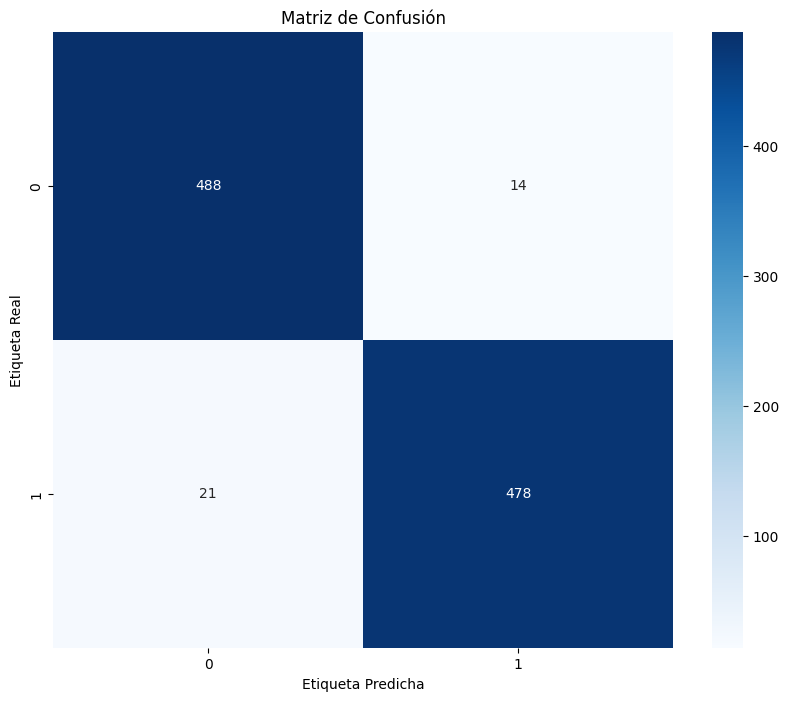

In [ ]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.ylabel('Etiqueta Real')
plt.xlabel('Etiqueta Predicha')
plt.show()

## RESUME

### 1. Data Loading
- Loaded our dataset

### 2. Data Cleaning
- Checked for possible outliers and missing values

### 3. Feature Engineering
- Performed label encoding
- Combined two features into one (forehead_ratio)
- Visualized the dataset
- Standardized the data
- Analyzed correlations

### 4. SVM Implementation with Pipelines

#### 4.1 Linear SVM
- Standard hyperparameters (C=1): Accuracy = 0.9530469530469531
- Experimented with C and tolerance
- GridSearch best hyperparameters:
  - 'svm__C': 0.1
  - 'svm__tol': 0.0001
- Best accuracy: 0.9530469530469531

#### 4.2 Polynomial SVM
- Standard hyperparameters (degree=3, C=1, coef0=1): Accuracy = 0.957042957042957
- Experimented with mentioned hyperparameters
- GridSearch best hyperparameters:
  - 'svm__C': 1
  - 'svm__gamma': 'scale'
- Best accuracy: 0.9630369630369631

#### 4.3 Gaussian SVM
- Standard hyperparameters (degree=3, C=1, coef0=1): Accuracy = 0.957042957042957
- Experimented with mentioned hyperparameters
- GridSearch best hyperparameters:
  - 'svm__C': 0.1
  - 'svm__gamma': 0.1
- Best accuracy: 0.965034965034965

### 5. Conclusion
- Gaussian SVM performed best
- Problem nature fits better with Gaussian kernel
- Dataset considered 'easy' due to clear data and good correlation with objective feature
